#Title and intro

In [1]:
# imports and constants

import numpy as np
import matplotlib.pyplot as plt

# Physical constants (values taken from project booklet, in SI units)
G = 6.67348e-11   # gravitational constant (m^3 kg^-1 s^-2)
M = 1.989e30      # mass of the Sun (kg)
R = 1.496e11      # Earth's mean orbital radius, 1 AU (m)

# Question 1 (core):

For an object with mass $m$ attached to a spring with spring constant $k$ that is undergoing simple oscillation, we can write its equation of motion as : $m\ddot{x} = -kx$, where the natural frequency is given by $\omega = \sqrt{k/m}$, the position of the object is given by $x = r$, the velocity of the object is given by $\dot{x} = v$ and the acceleration of the object is given by $\ddot{x} = a$. After solving this ODE, we obtain the general solutions for the position and the velocity of the object in terms of time $t$:

\begin{align}
r(t) &= C_1 \cos(\omega t) + C_2 \sin(\omega t) \\
v(t) &= C_2 \omega \cos(\omega t) - C_1 \omega \sin(\omega t) 
\end{align}

where $C_1$ and $C_2$ are arbitrary constants to be determined by initial conditions.

Assuming the initial conditions are $r(0) = r_0 , v(0) = v_0 ,$  we can find the particular solutions for both the position and the velocity:

\begin{align}
r(t) &= r_0 \cos(\omega t) + \frac{v_0}{\omega} \sin(\omega t) \\
v(t) &= v_0 \cos(\omega t) - r_0 \omega \sin(\omega t) 
\end{align}


And we can calculate the position and the velocity of an object at time $t$ by setting the parameters values for $ m, k, r_0, v_0, t$ accordingly using the function below:

In [2]:
import numpy as np

def position_velocity_exact (m, k, r0, v0,t):
    """
    This function takes 5 inputs that specifies the parameter values in the order 
    of: Mass(m), Spring Constant(k), Initial Position(r0), Initial Velocity(v0) and Time(t),
    and it returns the exact postion and the exact velocity of an object that is in simple oscillations
    with the input parameters at time t.
    """
    
    w = np.sqrt(k/m)
    r_exact = r0*np.cos(w*t) + (v0/w)*np.sin(w*t)
    v_exact = v0*np.cos(w*t) - r0*w*np.sin(w*t)

    return float(r_exact), float(v_exact)

print("Demonstartion: The exact position and the velocity of an object with mass 1 kg, spring constant 2, initial position 3 m, initial velocity 4 m/s at time 5 s is " + str(position_velocity_exact (1,2,3,4,5)))

Demonstartion: The exact position and the velocity of an object with mass 1 kg, spring constant 2, initial position 3 m, initial velocity 4 m/s at time 5 s is (4.121006224442668, -0.18605213304224488)


Alternatively, we can use the velocity Verlet algorithm to solve the same ODE. As stated above, the acceleration is given by $\ddot{x} = a = -\frac{kx}{m}$, and thus we can apply the algorithm:

\begin{align}
r_{n+1} &= r_n + v_n\,dt + \frac{1}{2}a(r_n)\,dt^2 \\
v_{n+1} &= v_n + \frac{1}{2}\left(a(r_n) + a(r_{n+1})\right)dt
\end{align}

where $r = x$, $v = \dot{r} = \dot{x}$, $dt$ is the time step, and $r_n$ and $v_n$ are the position and velocity of the object after $n$ steps, i.e. at time $t = n\,dt$. Substituting in the acceleration gives:

\begin{align}
r_{n+1} &= r_n + v_n\,dt - \frac{k}{2m}r_n\,dt^2 \\
v_{n+1} &= v_n - \frac{k}{2m}\left(r_n + r_{n+1}\right)dt
\end{align}

At each step the position $r_{n+1}$ must be calculated first, since the velocity update requires the acceleration at the new position. Starting with the initial conditions $x_0 = r_0$ and $v_0$ and repeating this for $N = t/dt$ steps gives approximations of the position and velocity at time $t$. We can calculate these using the function below:

In [3]:
def position_velocity_verlet (m,k, r0, v0, dt, N):
   
    """
    This function takes 6 inputs that specifies the parameter values in the order 
    of: Mass(m), Spring Constant(k), Initial Position(r0), Initial Velocity(v0), Time step(dt) and 
    Total Step Number (N) and it uses the velocity Verlet algorithm to approximate the postion and velocity of an object 
    that is in simple oscillations with the input parameters at the Nth step.
    """

    r = r0
    v = v0

    for n in range(N):
        r_new = r + (v * dt) - ((k * r / (2*m)) * (dt**2))
        v = v - k*(r + r_new) * dt/ (2 *m)
        r = r_new
        
    return float(r) , float (v)

print("Demonstartion: The position and the velocity of an object with mass 6 kg, spring constant 7, initial position 8 m, initial velocity 9 m/s approximated using the velocity Verlet algorithm with time step 0.1 at the 300th step is " + str(position_velocity_verlet (6,7,8,9,0.1,300)))


Demonstartion: The position and the velocity of an object with mass 6 kg, spring constant 7, initial position 8 m, initial velocity 9 m/s approximated using the velocity Verlet algorithm with time step 0.1 at the 300th step is (11.33616011029688, -2.441221236370682)


To see how the exact solutions differs from the Verlet approximations, we can plot and compare the position/time graph, $(t,x(t)=r(t))$ and the phase space trajectories $(x(t)=r(t),v(t))$ generated by both mehtods, using the functions below:

Demonstartion: The position/time graph and the phase space trajectories of an object in simple oscillation with mass 5 kg, spring constant 1, initial position 7 m, initial velocity 3 m/s generated exactly as well as using the velocity Verlet algorithm with time step 1.16 till the time 25 s are shown as below:


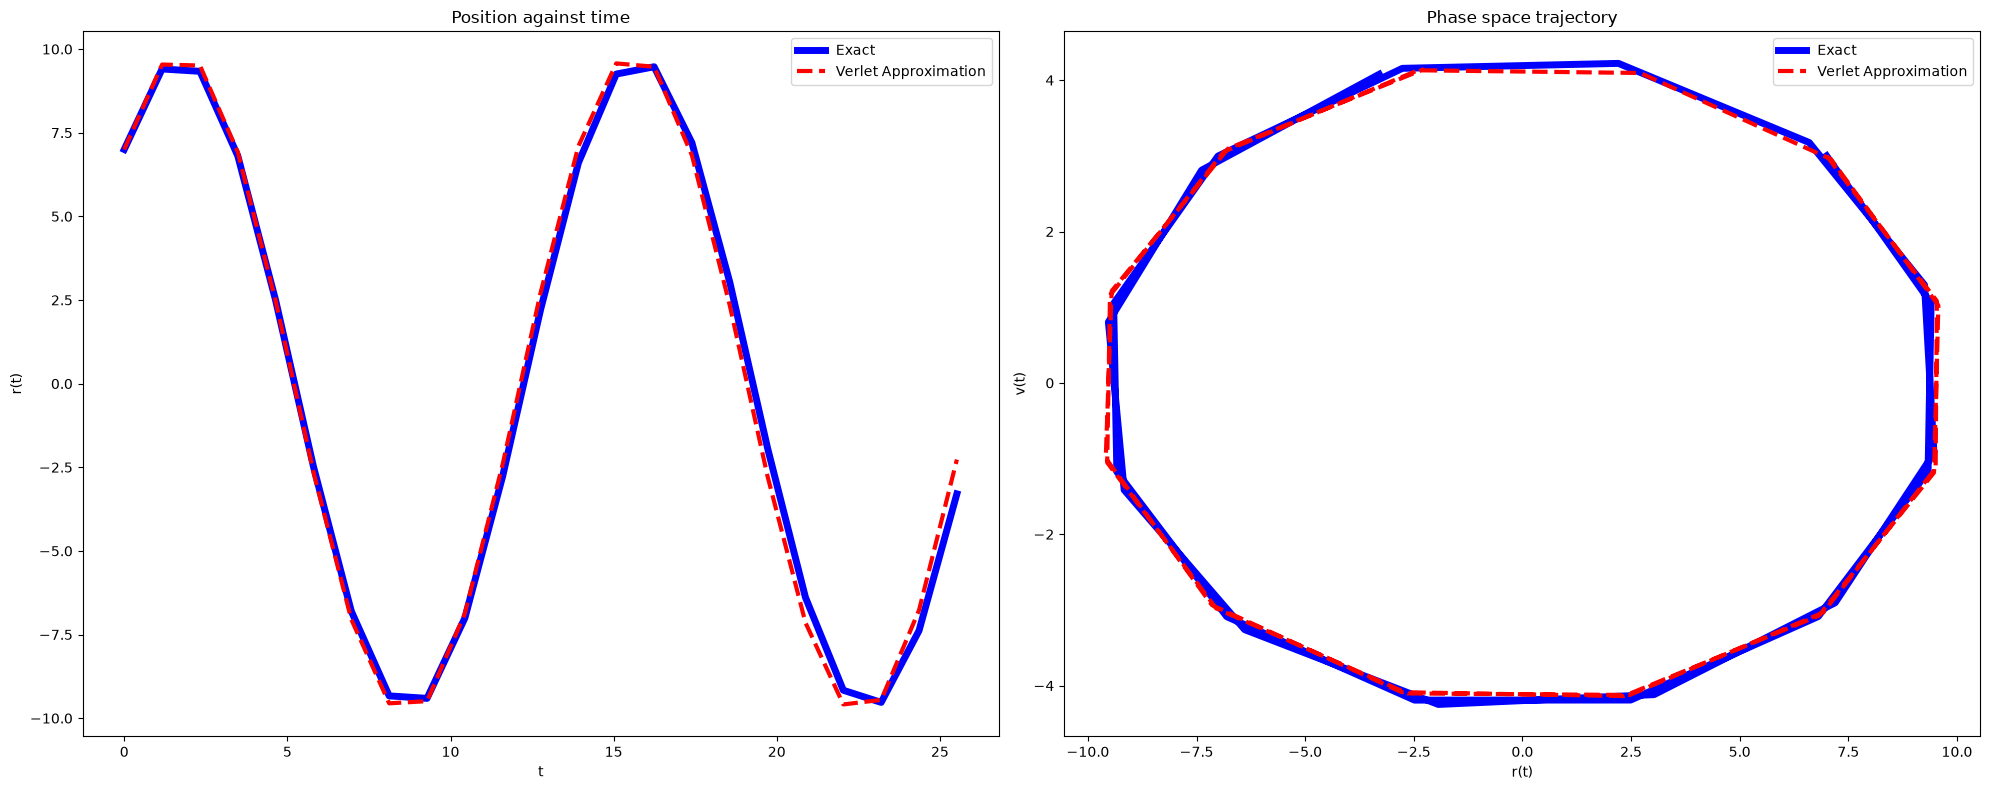

In [4]:
import matplotlib.pyplot as plt

def plot_compare(m,k, r0, v0, dt, t):
    """
    This function implements the 2 different methods to generate lists of position and velocity data of an object 
    that is in simple oscillations with the input parameters at the Nth step / time t using the function above and 
    plots the position/time graph and the phase space trajectories for each computation method on the same diagram
    as the output for comparison.
    """

    N = round(t/dt)
    time_at_steps = np.linspace(0, dt*N, N+1)
    r_exact = []
    v_exact = []
    r_verlet = []
    v_verlet = []

    for n in range(N+1):
        exact_r, exact_v = position_velocity_exact (m, k, r0, v0,time_at_steps[n])
        verlet_r, verlet_v = position_velocity_verlet (m,k, r0, v0, dt, n)
        r_exact.append(exact_r)
        v_exact.append(exact_v)
        r_verlet.append(verlet_r)
        v_verlet.append(verlet_v)

    fig, ax = plt.subplots(1, 2, figsize = (20,8))

    ax[0].plot(time_at_steps, r_exact, color = "blue", linewidth = 5, label = 'Exact')
    ax[0].plot(time_at_steps, r_verlet, "--", color = "red", linewidth = 3, label = 'Verlet Approximation')
    ax[0].set(xlabel="t", ylabel = "r(t)", title = "Position against time")
    ax[0].legend()
    ax[1].plot(r_exact, v_exact, color = "blue", linewidth = 5, label = 'Exact')
    ax[1].plot(r_verlet, v_verlet, "--",  color = "red", linewidth = 3, label = 'Verlet Approximation')
    ax[1].set(xlabel="r(t)", ylabel = "v(t)", title = "Phase space trajectory")
    ax[1].legend()

    plt.tight_layout()
    plt.show()

    return


print("Demonstartion: The position/time graph and the phase space trajectories of an object in simple oscillation with mass 5 kg, spring constant 1, initial position 7 m, initial velocity 3 m/s generated exactly as well as using the velocity Verlet algorithm with time step 1.16 till the time 25 s are shown as below:")
plot_compare(5,1,7,3,1.16,25)

If we set specific parameters for our objects, we can now compare the numerical solution with the exact solution on the Python generated plot and see the difference between the 2 methods of computation. For example, if we use an object with mass $6 kg$, spring constant 2, initial position $8 m$, initial velocity $4 m/s$, and choose the time step as 0.9 with the total time $30 s$, the 2 plots we obtain are as follows:

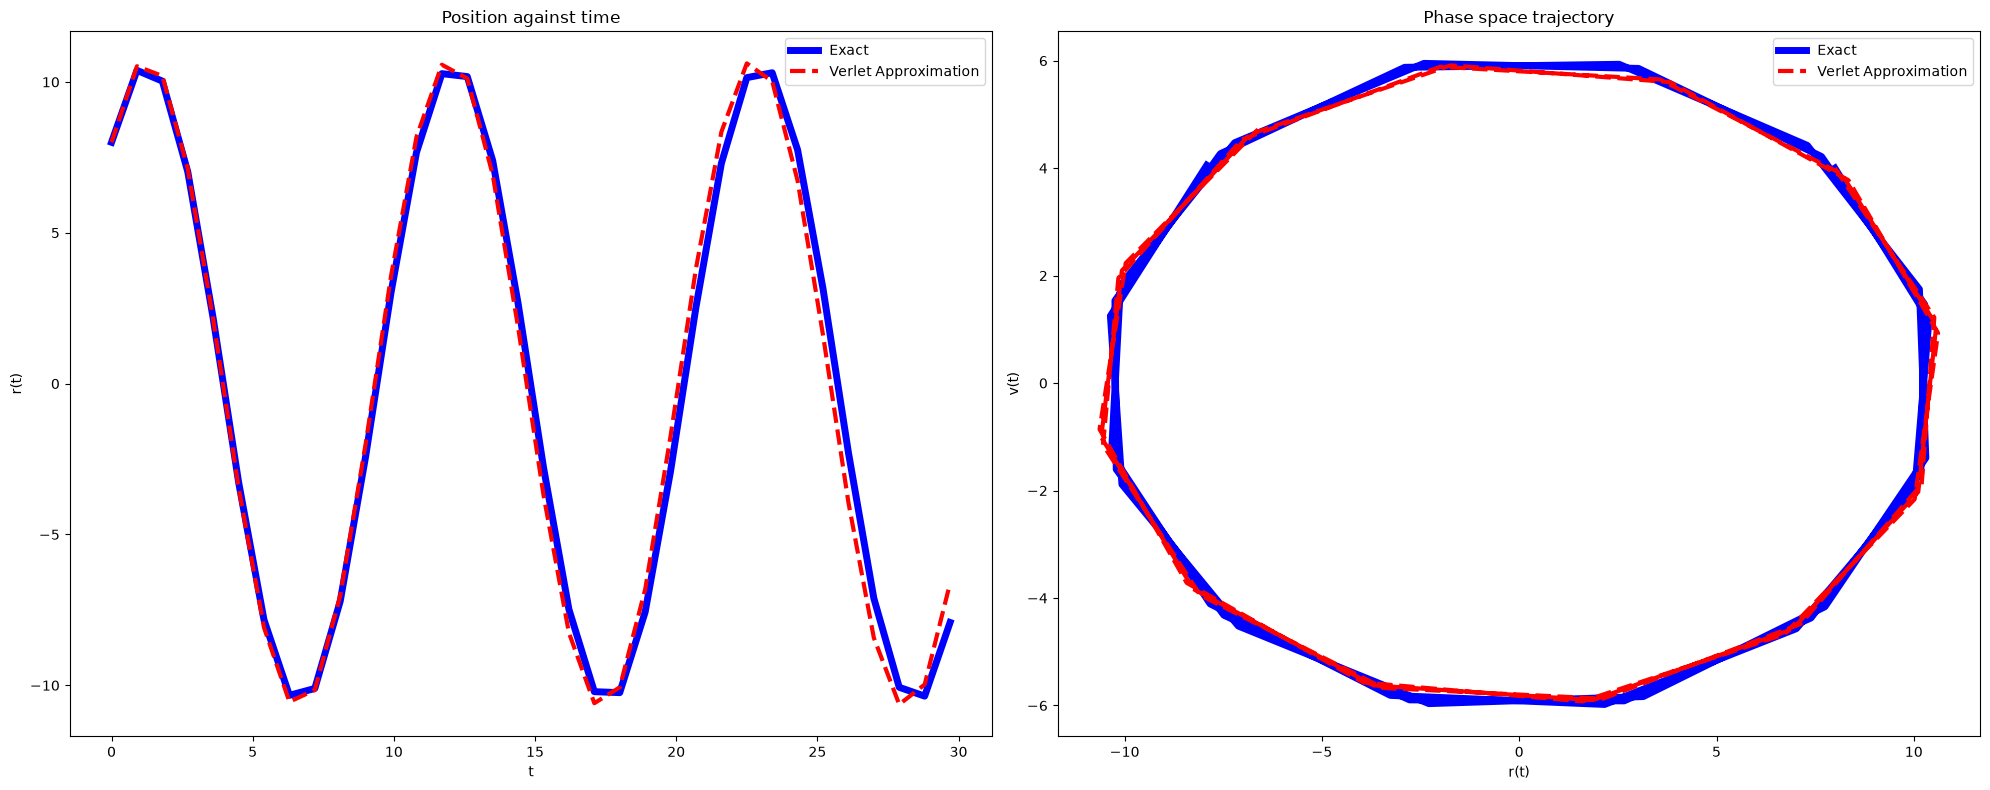

In [5]:
plot_compare(6,2,8,4,0.9,30)

The blue lines represent the exact solutions while the red dotted line represent the Verlet Approximation, and both graphs clearly shows that there is a noticable difference between the 2 lines given the set parameters. However, if we use the same set of parameters, but instead choose a much smaller time step, e.g. 0.09 instead of 0.9, the difference we would observe become much smaller, as shown below:

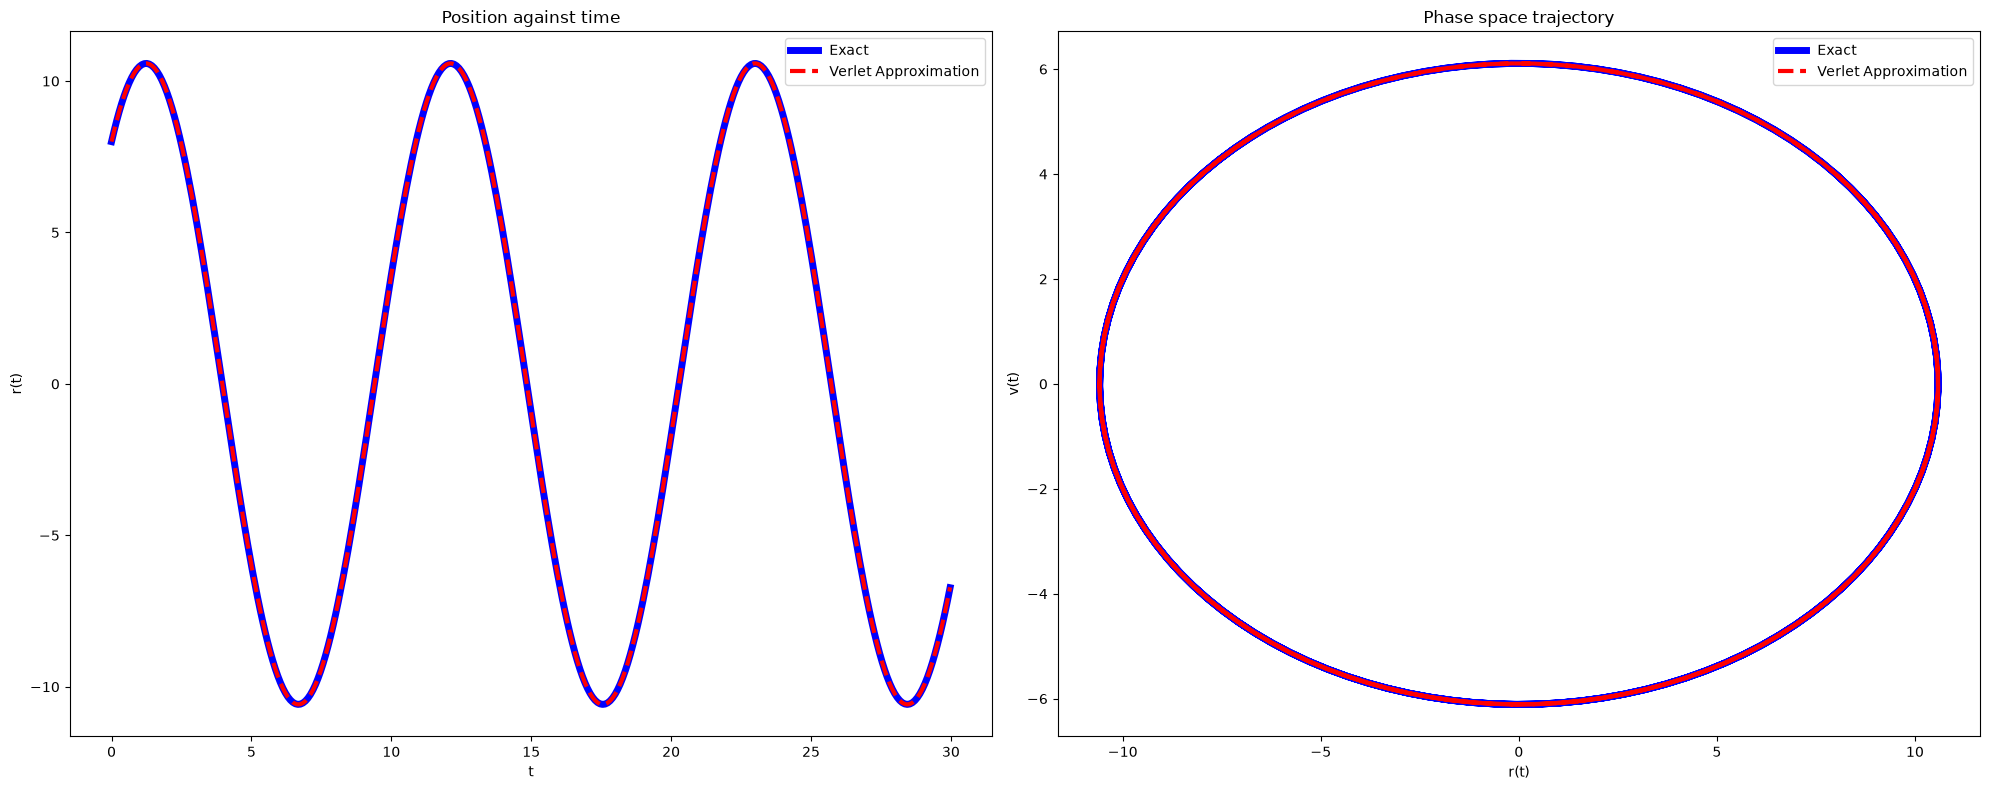

In [6]:
plot_compare(6,2,8,4,0.09,30)

We can see that in both graphs, the 2 lines basically overlap each other, which means that if the time step is reasonably small, the velocity Verlot algorithm become indistinguishable in practice from the exact solution for simple oscillations.

## Core 2: Motion of an earth like planet around the Sun

Simulating the motion of an Earth like planet around the Sun.
We assume the Sun to be fixed at the origin as it is about 330,000 times more massive than the Earth so its motion is negligible.
This simulation is purely in the $xy$ plane. 
The planet begins at a radius 1.496e11m (1AU) away from the sun and with velocity 29.8 km/s, perpendicular to the line towards the Sun.

### Gravitational acceleration: `g_accel(r)`

By Newton's law of gravitation, the acceleration of the planet at position $\mathbf{r}$ is

$$\mathbf{a}(\mathbf{r}) = -\frac{GM}{|\mathbf{r}|^3}\,\mathbf{r}$$

### Velocity Verlet method

We write the equation of motion as two first-order equations:

$$\dot{\mathbf{r}} = \mathbf{v}, \qquad \dot{\mathbf{v}} = \mathbf{a}(\mathbf{r})$$

and step them forward in time using the velocity Verlet algorithm with time step $dt$.

**Position update: `next_r(r_k, v_k, dt)`**

$$\mathbf{r}_{k+1} = \mathbf{r}_k + \mathbf{v}_k\,dt + \frac{1}{2}\mathbf{a}(\mathbf{r}_k)\,dt^2$$

**Velocity update: `next_v(r_k, r_k_plus_1, v_k, dt)`**

$$\mathbf{v}_{k+1} = \mathbf{v}_k + \frac{1}{2}\left(\mathbf{a}(\mathbf{r}_k) + \mathbf{a}(\mathbf{r}_{k+1})\right)dt$$

The velocity update averages the acceleration at the old and new positions, so the new position must be calculated first.

The velocity Verlet is used as it's symplectic, so the total energy does not drift over long simulations, but oscillates by a small bounded amount which is negligible in our calculations.

In [7]:

def g_accel(r: np.ndarray) -> np.ndarray:
    """
    Gravitational acceleration of a body at position r with sun fixed at the origin
    r: current position vector (numpy array)
    Returns a = -GM r / |r|^3
    """
    return -G * M * r / np.linalg.norm(r)**3

def next_r(r_k: np.ndarray, v_k: np.ndarray, dt: float) -> np.ndarray:
    """
    Velocity Verlet position update: r_(k+1) = r_k + v_k dt + 1/2a(r_k) dt^2
    r_k: Current position vector of the body (numpy array)
    v_k: Current velocity vector of the body (numpy array)
    dt: Time step for the simulation, the smaller, the more accurate ((dt)^3 error) (float)
    uses g_accel(r) for gravitational acceleration
    """
    return r_k + v_k * dt + 0.5 * g_accel(r_k) * dt**2

def next_v(r_k: np.ndarray, r_k_plus_1: np.ndarray, v_k: np.ndarray, dt: float) -> np.ndarray:
    """
    Velocity Verlet velocity update: v_(k+1) = v_k + 1/2(a(r_k) + a(r_(k+1))) dt
    r_k: Current position vector of the body (numpy array)
    r_k_plus_1: Next position vector of the body (numpy array)
    v_k: Current velocity vector of the body (numpy array)
    dt: Time step for the simulation, the smaller the more accurate (float)
    uses g_accel(r) for gravitational acceleration
    """
    return v_k + 0.5 * (g_accel(r_k) + g_accel(r_k_plus_1)) * dt


In [8]:
 
r_0 = R * np.array([1, 0])  # Initial position vector (1 AU from the Sun)
v_0 = 29.8e3 * np.array([0, 1])  # Initial velocity vector (29.8km/s along +y direction)
dt = 60 * 60 * 12 # 12 Hours time frame

r, v = r_0, v_0
positions = [r]
velocities = [v]
for i in range(730): # Simulate for a year
    r_next = next_r(r, v, dt)  # Update position 
    v_next = next_v(r, r_next, v, dt)  # Update velocity 
    r = r_next  # Update the current position for the next iteration
    v = v_next # Update the current velocity for the next iteration
    positions.append(r)
    velocities.append(v)



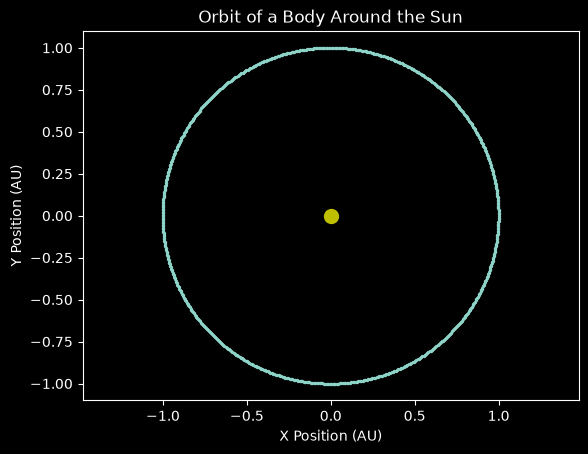

In [9]:
# Plot of orbit
# Convert positions to a numpy array for easier plotting
plt.style.use('dark_background')

positions = np.array(positions)
velocities = np.array(velocities)
plt.scatter(positions[:, 0] / R, positions[:, 1] / R, s=2)
plt.plot(0, 0, 'yo', markersize=10)  # Plot the Sun at the origin
plt.axis('equal')
plt.title("Orbit of a Body Around the Sun")
plt.xlabel("X Position (AU)")
plt.ylabel("Y Position (AU)")
plt.show()

The orbit is closed and stays within 0.2% of 1 AU.

# Question 3 (core) 

#### In this question we verify that a closed orbit is found using the verlet algorithm, also checking that the total energy remains constant. An analytical derived solution for v0 is also found at the bottom.

##### Verifying the orbit is closed: 

We have that the acceleration vector field (ax, ay) can be defined by:

$a\hat{x} = \frac{-GMr\hat{x}}{|r^3|}$


$a\hat{y} = \frac{-GMr\hat{y}}{|r^3|}$

Now that we have the acceleration functions, we can use the velocity Verlet algorithm:

$$\mathbf{r}_{k+1} = \mathbf{r}_k + \mathbf{v}_k \, dt + \frac{1}{2} \mathbf{a}(\mathbf{r}_k) \, dt^2$$
 

$$\mathbf{v}_{k+1} = \mathbf{v}_k + \frac{1}{2} \big( \mathbf{a}(\mathbf{r}_k) +  \mathbf{a}(\mathbf{r}_{k+1})\big) \, dt$$

Setting the values for G(gravational constant) and M(Mass of the sun), and the initial velocity and position, we can create a loop which appends a storage array (storing the postion of the planet) using the velocity Verlet algorithm, giving us an array we can use to plot the trajectory of the planet, and verifying that the planet's orbit is a closed loop (which we do indeed find looking at the outputs below the code cell). 

##### Verifying that the total energy stays constant:

As for verifying that the energy stays constant, all that is left to do is define a function for the total energy by summing the kinetic energy and potential energy: $\textbf{E = T + V}$. 

$\textbf{T} = \frac{1}{2} \sum_{i} m_i |\dot{\mathbf{r}}_i|^2$

$\textbf{V} = -G \sum_{i>j} \frac{m_i m_j}{|\mathbf{r}_j - \mathbf{r}_i|}.$

By creating an storage list for the total energy (E) at each time step, we can plot a graph to verify that the total energy stays constant. This graph can be seen in the outputs of the code cell below, and we can indeed see that E remains constant throughout the orbit. 

We have the first graph representing 2d space, with the orbit depicted by the blue curve, and the central body depicted by the red dot at the origin:

The second plot reveals that the total energy stays constant during the orbital period with time on the x-axis and energy on the y-axis:


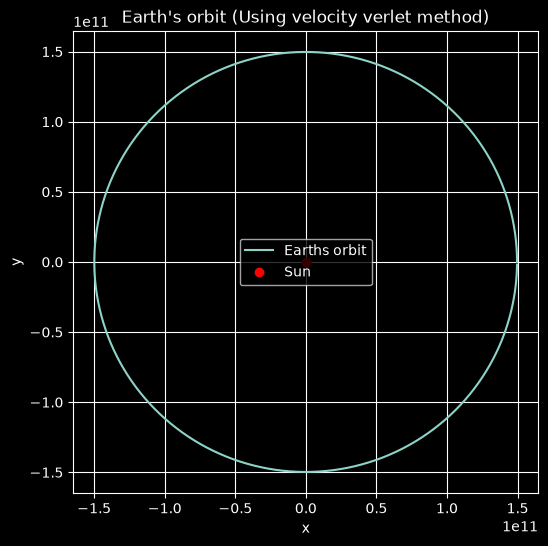

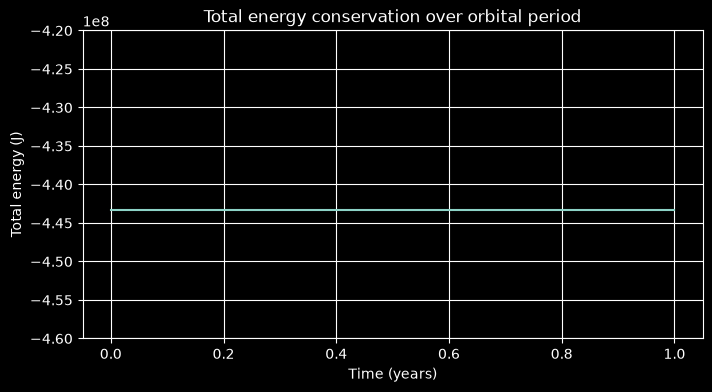

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Fixing the parameters
G = 6.67348e-11
Mass_sun = 1.989e30
R_orbit = 149.6e9

# Creating arrays to later be used for the planets velocity and position values
r0 = np.array([R_orbit, 0.0])
v0 = np.array([0.0, 29800.0])

# Defining the acceleration function to be used for the algorithm. 
def acceleration(r):
    x = r[0]
    y = r[1]

    r_abs = (x**2 + y**2) ** 0.5
    ax = -G * Mass_sun * x / (r_abs**3)
    ay = -G * Mass_sun * y / (r_abs**3)

    return np.array([ax, ay])

# Setting the time step as 1 day (in seconds) and the number of steps as the number of days in a year. 
dt = 86400
steps = int((366 * 24 * 3600) / dt)

# Creating new arrays for the position and velocity values using the initial values. 
r = np.array(r0)
v  = np.array(v0)

# Creating lists to be appended in the algorithm 
r_orbit = []
energy = []
t = []

# Defining the total energy function 
def total_energy(pos_vec, vel_vec, mass=1.0):
    
    T = 0.5 * mass * (vel_vec[0]**2 + vel_vec[1]**2)
    r_abs = (pos_vec[0]**2 + pos_vec[1]**2)**0.5
    V = -G * Mass_sun * mass / r_abs
    
    return T + V

# Applying the velocity verlet algorithm 
for step in range(steps):
    r_orbit.append(r)
    energy.append(total_energy(r, v))
    t.append(step * dt)

    a = acceleration(r)
    r_update = r + v * dt + 0.5 * a * (dt**2)
    a_update = acceleration(r_update)
    v_update = v + 0.5 * (a + a_update) * dt 

    r = r_update 
    v = v_update 

r_orbit = np.array(r_orbit)

# plotting required results
print('We have the first graph representing 2d space, with the orbit depicted by the blue curve, and the central body depicted by the red dot at the origin:')
    
plt.figure(figsize=(6, 6))
plt.plot(r_orbit[:, 0], r_orbit[:, 1], label='Earths orbit')
plt.plot(0, 0, "ro", label='Sun')
plt.title("Earth's orbit (Using velocity verlet method)")
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show 

print()

print('The second plot reveals that the total energy stays constant during the orbital period with time on the x-axis and energy on the y-axis:')

plt.figure(figsize=(8, 4))
plt.plot(np.array(t) / (365 * 24 * 3600), energy)
plt.title('Total energy conservation over orbital period')
plt.xlabel('Time (years)')
plt.ylabel('Total energy (J)')
plt.grid(True)
plt.ylim(-4.6e8, -4.2e8)
plt.show()


#### Analytical derivation of initial speed v0:





For a circular orbit of radius \(r\), the gravitational force provides the required centripetal force. Using Newton's law of universal gravitation and the equation for circular motion:
\begin{equation*}
    \frac{G M m}{r^2} = \frac{m v_0^2}{r}
\end{equation*}
where \(M\) is the mass of the Sun, \(m\) is the mass of the orbiting body (the Earth), and \(r = R\) is the orbital radius. 

Canceling the mass of the orbiting body \(m\) and one factor of \(r\) from the denominator gives:
\begin{equation*}
    \frac{G M}{R} = v_0^2
\end{equation*}
Taking the square root yields the analytical expression for the orbital speed:
\begin{equation*}
    v_0 = \sqrt{\frac{G M}{R}}
\end{equation*}



# Question 4 (core):

We now look at how changing the initial speed of the planet affects its orbit. We keep the Sun fixed at the origin and start the planet at $\mathbf{r}_0=(R,0)$, with an initial velocity $\mathbf{v}_0=(0,v_0)$, where $v_0>0$. This means that we change the speed without changing the direction of motion.

To simulate the orbits, we use the velocity Verlet method from Question 2 and the energy function from Question 3. We use a time step of half a day.

In [11]:
# Use constants from Core 3
q4_G = G
q4_M = M  # REMOVE IN POST AND CHANGE ALL q4 values to standard ones just left in for now so code runs


q4_R = R
q4_dt = 12 * 60 * 60
q4_v_circular = np.sqrt(q4_G * q4_M / q4_R)
q4_v_escape = np.sqrt(2 * q4_G * q4_M / q4_R)

# Simulate an orbit
def q4_simulate_orbit(speed, dt, steps):
    r = np.array([q4_R, 0.0])
    v = np.array([0.0, speed])
    positions = [r]
    for i in range(steps):
        r_next = next_r(r, v, dt)
        v = next_v(r, r_next, v, dt)
        r = r_next
        positions.append(r)
    return np.array(positions)

def q4_initial_energy(v):
    return total_energy(np.array([q4_R, 0.0]), np.array([0.0, v]))

# Period of a bound orbit
def q4_orbital_period(v):
    a = -q4_G * q4_M / (2 * q4_initial_energy(v))
    return 2 * np.pi * np.sqrt(a**3 / (q4_G * q4_M))

## Effect of initial speed
We compare five initial speeds below the escape speed. Each bound orbit is simulated for at least one theoretical orbital period, rather than using one year for every speed. This allows the more extended orbits to reach aphelion. The period follows from $T=2\pi\sqrt{a^3/(GM)}$, where $a=-GM/(2\mathcal E_0)$ and $\mathcal E_0=v_0^2/2-GM/R$.

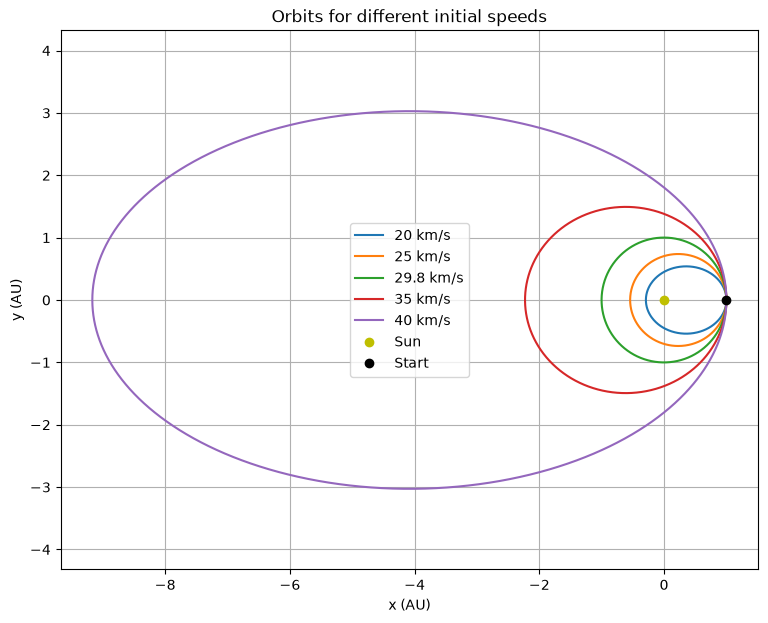

In [12]:
plt.style.use('default')
q4_speeds = [20, 25, 29.8, 35, 40]
q4_orbits = []
plt.figure(figsize=(9, 7))
for q4_speed in q4_speeds:
    q4_v = q4_speed * 1000
    q4_steps = int(q4_orbital_period(q4_v) / q4_dt) + 1
    q4_positions = q4_simulate_orbit(q4_v, q4_dt, q4_steps)
    q4_orbits.append(q4_positions)
    plt.plot(q4_positions[:, 0] / q4_R, q4_positions[:, 1] / q4_R,
             label=str(q4_speed) + " km/s")
plt.plot(0, 0, 'yo', label='Sun')
plt.plot(1, 0, 'ko', label='Start')
plt.axis('equal')
plt.xlabel('x (AU)')
plt.ylabel('y (AU)')
plt.title('Orbits for different initial speeds')
plt.legend()
plt.grid(True)
plt.show()

The orbit at 29.8 km/s is nearly circular. Lower speeds start near aphelion and move closer to the Sun, while higher speeds start at perihelion and reach larger distances. The 40 km/s orbit is much more extended than the other examples.

## Orbital parameters
Conservation of angular momentum gives $h=Rv_0$. At a turning point the radial velocity is zero, so
$$\mathcal E_0=\frac{h^2}{2r^2}-\frac{GM}{r}.$$
Substituting the initial energy gives a quadratic in $r$:
$$2\mathcal E_0r^2+2GMr-h^2=0.$$
One root is $R$ because the initial velocity is tangential. The other is
$$r_2=\frac{R^2v_0^2}{2GM-Rv_0^2}.$$
For $0<v_0<v_{\rm esc}$,
$$P=\min(R,r_2),\quad A=\max(R,r_2),\quad a=\frac{A+P}{2},\quad b=\sqrt{AP},\quad e=\frac{A-P}{A+P}.$$
We estimate $P$ and $A$ from the minimum and maximum simulated distance to the Sun, and calculate the other parameters using the same formulas.

In [13]:
def q4_parameters(P, A):
    a = (A + P) / 2
    b = np.sqrt(A * P)
    e = (A - P) / (A + P)
    return P, A, a, b, e

# Theoretical ellipse parameters
def q4_ellipse_values(v):
    r2 = q4_R**2 * v**2 / (2 * q4_G * q4_M - q4_R * v**2)
    return q4_parameters(min(q4_R, r2), max(q4_R, r2))

# Compare theory and simulation
print('Speed | Source | P/R | A/R | a/R | b/R | e')
for q4_i in range(len(q4_speeds)):
    q4_speed = q4_speeds[q4_i]
    q4_theory = q4_ellipse_values(q4_speed * 1000)
    q4_positions = q4_orbits[q4_i]
    q4_distances = np.sqrt(q4_positions[:, 0]**2 + q4_positions[:, 1]**2)
    q4_numerical = q4_parameters(min(q4_distances), max(q4_distances))
    q4_P, q4_A, q4_a, q4_b, q4_e = q4_theory
    print(q4_speed, 'Theory', round(q4_P/q4_R, 5), round(q4_A/q4_R, 5),
          round(q4_a/q4_R, 5), round(q4_b/q4_R, 5), round(q4_e, 5))
    q4_P, q4_A, q4_a, q4_b, q4_e = q4_numerical
    print(q4_speed, 'Simulation', round(q4_P/q4_R, 5), round(q4_A/q4_R, 5),
          round(q4_a/q4_R, 5), round(q4_b/q4_R, 5), round(q4_e, 5))
    print('Maximum turning-point error (AU):',
          round(max(abs(q4_theory[0]-q4_numerical[0]), abs(q4_theory[1]-q4_numerical[1]))/q4_R, 6))
    print()

Speed | Source | P/R | A/R | a/R | b/R | e
20 Theory 0.29101 1.0 0.6455 0.53945 0.54918
20 Simulation 0.29119 1.0 0.64559 0.53962 0.54896
Maximum turning-point error (AU): 0.00018

25 Theory 0.5437 1.0 0.77185 0.73736 0.29559
25 Simulation 0.54376 1.0 0.77188 0.7374 0.29554
Maximum turning-point error (AU): 5.9e-05

29.8 Theory 1.0 1.00174 1.00087 1.00087 0.00087
29.8 Simulation 1.0 1.00178 1.00089 1.00089 0.00089
Maximum turning-point error (AU): 3.7e-05

35 Theory 1.0 2.22914 1.61457 1.49303 0.38064
35 Simulation 1.0 2.22921 1.61461 1.49305 0.38065
Maximum turning-point error (AU): 7e-05

40 Theory 1.0 9.16701 5.0835 3.02771 0.80329
40 Simulation 1.0 9.16785 5.08392 3.02785 0.8033
Maximum turning-point error (AU): 0.000841



Small differences are expected because velocity Verlet has finite time-step error and the sampled positions may not fall exactly at the turning points. The absolute turning-point error is useful even for nearly circular orbits, where relative eccentricity error can be misleading.

## Classification of orbits
The initial specific orbital energy is
$$\mathcal E_0=\frac12v_0^2-\frac{GM}{R}.$$
For a nonzero tangential initial velocity, negative energy gives an ellipse (including a circle), zero energy gives a parabola and positive energy gives a hyperbola. We use a small absolute tolerance for floating-point round-off when comparing energy with zero. The three trajectories below are shown over the same finite time interval; an open trajectory does not by itself prove escape.

Speed (km/s) | Energy (J/kg) | Orbit
20.0 -687269500.0 Ellipse
29.8 -443249500.0 Ellipse
40.0 -87269500.0 Ellipse
42.125277 0.0 Parabola
45.0 125230500.0 Hyperbola


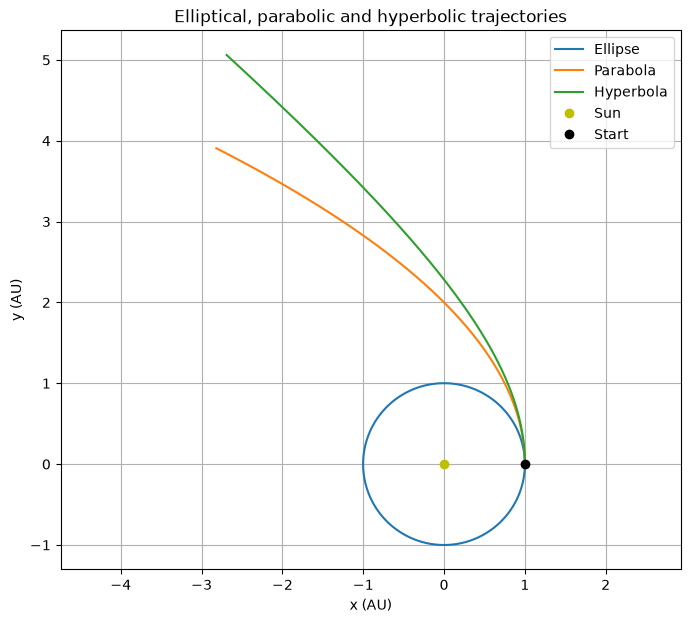

In [14]:
def q4_orbit_type(v):
    E = q4_initial_energy(v)
    if abs(E) < 0.001:
        return 'Parabola'
    if E < 0:
        return 'Ellipse'
    return 'Hyperbola'

print('Speed (km/s) | Energy (J/kg) | Orbit')
for q4_v in [20000, 29800, 40000, q4_v_escape, 45000]:
    print(round(q4_v/1000, 6), round(q4_initial_energy(q4_v), 2), q4_orbit_type(q4_v))

# Compare three orbit types over one year
plt.figure(figsize=(8, 7))
for q4_v in [29800, q4_v_escape, 45000]:
    q4_positions = q4_simulate_orbit(q4_v, q4_dt, 730)
    plt.plot(q4_positions[:, 0]/q4_R, q4_positions[:, 1]/q4_R,
             label=q4_orbit_type(q4_v))
plt.plot(0, 0, 'yo', label='Sun')
plt.plot(1, 0, 'ko', label='Start')
plt.axis('equal')
plt.xlabel('x (AU)')
plt.ylabel('y (AU)')
plt.title('Elliptical, parabolic and hyperbolic trajectories')
plt.legend()
plt.grid(True)
plt.show()

In [15]:
# Test the circular orbit and all three classifications
q4_P, q4_A, q4_a, q4_b, q4_e = q4_ellipse_values(q4_v_circular)
if abs(q4_P/q4_R-1) < 1e-8 and abs(q4_A/q4_R-1) < 1e-8 and q4_e < 1e-8:
    print('Circular orbit: PASS')
else:
    print('Circular orbit: FAIL')

q4_test_speeds = [20000, q4_v_escape, 45000]
q4_expected_types = ['Ellipse', 'Parabola', 'Hyperbola']
for q4_i in range(len(q4_test_speeds)):
    q4_result = q4_orbit_type(q4_test_speeds[q4_i])
    q4_expected = q4_expected_types[q4_i]
    if q4_result == q4_expected:
        print(q4_expected, ':', 'PASS')
    else:
        print(q4_expected, ':', 'FAIL')

Circular orbit: PASS
Ellipse : PASS
Parabola : PASS
Hyperbola : PASS


# Core 4: Determining the escape speed of an Earth like planet from the Sun's Gravitational field   

## Derivation

At escape speed, the planet just reaches infinity with zero speed, so $T = 0$ and $V = 0$ there.

By conservation of energy:

$$T_{initial} + V_{initial} = T_{\infty} + V_{\infty} $$

$$\frac{1}{2} m v_0^2 - \frac{GMm}{R} = 0 + 0$$

$$\frac{1}{2} m v_0^2 = \frac{GMm}{R}$$

The $m$ cancels:

$$\frac{1}{2} v_0^2 = \frac{GM}{R}$$

$$v_0^2 = \frac{2GM}{R}$$

$$v_{esc} = \sqrt{\frac{2GM}{R}}$$

Substituting $G = 6.67348 \times 10^{-11}$, $M = 1.989 \times 10^{30}$ kg and $R = 1.496 \times 10^{11}$ m:

$$v_{esc} = \sqrt{\frac{2 \times 6.67348 \times 10^{-11} \times 1.989 \times 10^{30}}{1.496 \times 10^{11}}}$$

$$v_{esc} \approx 4.213 \times 10^4 \text{ m/s} = 42.13 \text{ km/s}$$


In [16]:

def escape_check(v0, r_max, dt):
    """
    Simulates a planet starting at distance R from the Sun with speed v0 in the y directon.
    Returns 'remains in orbit' or 'escaped orbit' based on if it moves back towards the sun or moves away 
    v0: initial speed (m/s)
    r_max: distance beyond which the planet counts as escaped (m)
    dt: time step (s)
    """
    r = R * np.array([1,0])
    v = v0 * np.array([0,1])

    while True: 
        # One velocity verlet step
        r_next = next_r(r, v, dt)
        v = next_v(r, r_next, v, dt)
        r = r_next

        # Moving back towards the sun means bound orbit
        # If the dot product is less than 0 then the velocity is pointing towards the Sun partially
        if np.dot(r, v) < 0:
            return "remains in orbit"

        # The same angle test does not work for determining escape so we test if it has exceeded the maximum radius of orbit
        if np.linalg.norm(r) > r_max:
            return "escaped orbit"

def finding_escape_speed(r_max, dt, low_estimate = 25e3, high_estimate = 100e3, tol=1):
    """
    Uses bisection to find the escape speed, with a tolerance of 1 m/s
    r_max: distance beyond which the planet counts as escaped (m)
    dt: time step (s)
    low_estimate, high_estimate: starting values that we know the former maintains orbit and the latter escapes it. (m/s)
    tol: function stops when high minus low estimates is below our tolerance
    """
    while tol < high_estimate - low_estimate:
        # Test the midpoint of the two estimates
        midpoint = (high_estimate + low_estimate) / 2
        
        if escape_check(midpoint, r_max, dt) == "escaped orbit":
            # Planet escaped so the escape speed is below the midpoint
            high_estimate = midpoint
        else: 
            # Remained in orbit so the escape speed is above the midpoint
            low_estimate = midpoint

    return (low_estimate + high_estimate) / 2

    

The biggest problem here is the use of $r_{\max}$ to determine when a planet is considered escaped. For any simulation based method there will have to be some error.

The error shrinks in proportion to $1/r_{\max}$ and we can increase $r_{\max}$ to reduce the error but this will greatly increase the simulation time.   
Next we will show the increase in $r_{\max}$ brings us closer and closer to the theoretical escape speed.


r_max = 10 AU, escape speed = 40.1643 km/s
-> energy per kg = -8.068e+07 J/kg
r_max = 20 AU, escape speed = 41.1096 km/s
-> energy per kg = -4.227e+07 J/kg
r_max = 30 AU, escape speed = 41.4397 km/s
-> energy per kg = -2.864e+07 J/kg
r_max = 50 AU, escape speed = 41.7092 km/s
-> energy per kg = -1.744e+07 J/kg
r_max = 100 AU, escape speed = 41.9152 km/s
-> energy per kg = -8.826e+06 J/kg
Extrapolated escape speed: 42.1233 km/s
Theoretical escape speed:  42.1253 km/s


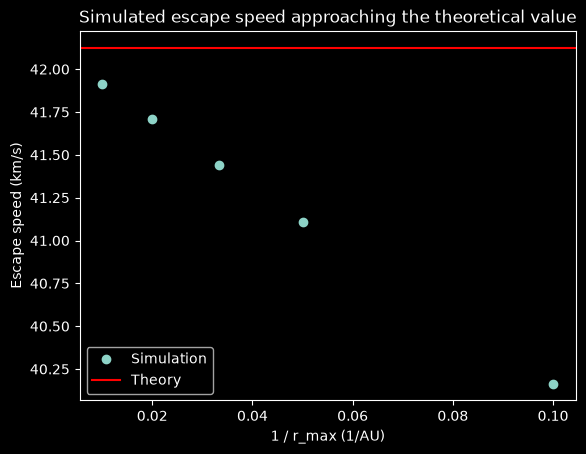

In [17]:

dt_escape = 60 * 60 * 24                  # time step: 1 day (s)
r_max_values = [10, 20, 30, 50, 100]      # cut-off distances for orbit for each simulation (AU)
escape_speed_simulations = []

# Simulated escape speed for each cut-off distance
for r_max_AU in r_max_values:
    v_4sim = finding_escape_speed(r_max_AU * R, dt_escape)
    escape_speed_simulations.append(v_4sim / 1000)          # store in km/s
    print("r_max =", r_max_AU, "AU, escape speed =", round(v_4sim / 1000, 4), "km/s")
    print("-> energy per kg =", f"{q4_initial_energy(v_4sim):.3e}", "J/kg")

# Show how increasing r_max to infinity will result in approaching theoretical value
x = 1 / np.array(r_max_values)
fit = np.polyfit(x, escape_speed_simulations, 2)
print("Extrapolated escape speed:", round(fit[-1], 4), "km/s")
print("Theoretical escape speed: ", round(q4_v_escape / 1000, 4), "km/s")

# Plot
plt.style.use('dark_background')
plt.plot(x, escape_speed_simulations, 'o', label="Simulation")
plt.axhline(q4_v_escape / 1000, color='red', label="Theory")
plt.xlabel("1 / r_max (1/AU)")
plt.ylabel("Escape speed (km/s)")
plt.title("Simulated escape speed approaching the theoretical value")
plt.legend()
plt.show()

The plot shows that as $r_{\max}$ increases, it approaches the theoretical value we calculated before.  
From 40.1643 km/s with $r_{\max}$ = 10 AU to 41.9152 km/s at $r_{\max}$ = 100 AU, approaching the theoretical 42.13 km/s.  

For any $r_{\max}$ value below infinity, the escape speed will always be under the theoretical one since the method finds the speed where the aphelion equals $r_{\max}$, which will always be slightly under the true escape speed.

At each simulated speed the energy per kg is negative, but it is approaching 0 as $r_{\max}$ is increasing.


# STILL TO DO - CALCULATION USING POINTS PLOTTED TO DETERMINE R_MAX VALUE AT R = INFINITY 


In [18]:
#Extension 5 

# Question 5 (Optional)

Kepler's second law, also called the law of equal areas, states that given a vector connecting the Sun and the Planet in orbit, the area swept by the planet via the vector, $A$ , in a fixed time period is constant, as in the areal velocity remains the same at all points and all time regardless of the trajectory type. Mathematically, we write:

$$
\frac{dA}{dt} = \frac{\bar{A}}{T} = constant
$$

where $\bar{A}$ represents the total area inside any orbit and $T$ is the total time for 1 orbit around the Sun by the planet.

Indeed we can test and verify Kepler's second law using the functions we built above that simulates the Earth-Sun orbital motion. From the previous code, we can build new functions that computes the area swept by the Earth inside the orbit during a set time period, and we will run several comparisons between different sets of start time and end time to see whether the area computed differs from one and another. In addition, because the Earth-Sun orbit is almost circular, we will repeat this test on other planets that follows an elliptical trajectory around the Sun by changing the parameters in our functions to see if the law holds universally. Furthermore, we will also use the Plot function to provide a graphical output that highlights the results of each of the computations in our tests.

In [19]:
# Code and output here

Below is the code to simulate Kepler's second law, using previously written functions for position.

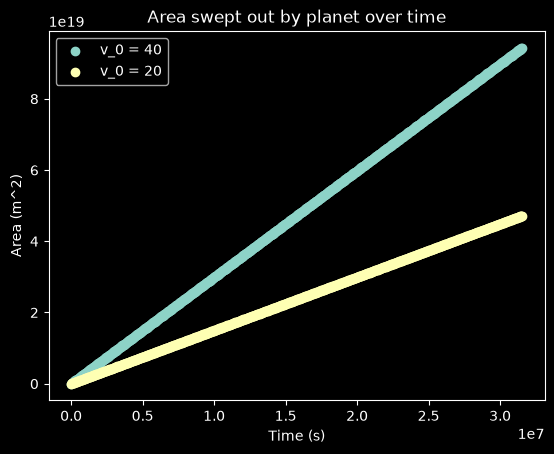

In [20]:
def calculate_area(r_k,r_k_plus_1):
    """Calculate area swept out by the planet between two positions"""
    return 0.5 * abs(r_k[0] * r_k_plus_1[1] - r_k_plus_1[0] * r_k[1])  # Cross-product = area of a triangle formed by the two position vectors


def calculate_total_area(t:float, orbital_position, dt:float)->float:
    """Calculate area swept out up to time t"""
    area = 0.0
    time = 0.0
    x_init = 0.0
    y_init = 0.0
    while time < t:
        if t - time < dt:
            dt = t - time
        
        x, y = orbital_position(time)
        area += calculate_area(np.array([x_init, y_init]), np.array([x, y]))
        
        x_init = x
        y_init = y
        time += dt
    return area
def area_swept_out(v_0,dt=60*60*12) -> float:
    """Calculate area swept out by the planet up to time t"""
    r = r_0
    v = v_0
    area_swept = [0]
    time = [0]
    for i in range(365 * 2):  # Simulate for 1 year, with a half-day time step
        r_next = next_r(r, v, dt)
        v_next = next_v(r, r_next, v, dt)
        
        added_area = calculate_area(r, r_next)

        area_swept.append(added_area+area_swept[-1])
        time.append(time[-1] + dt)

        r = r_next
        v = v_next
    return time, area_swept

times1,area_swept1 = area_swept_out(40,dt=60*60*12)
times2,area_swept2 = area_swept_out(20,dt=60*60*12)


plt.scatter(times1, area_swept1, label='v_0 = 40')
plt.scatter(times2, area_swept2, label='v_0 = 20')
plt.title("Area swept out by planet over time")
plt.xlabel("Time (s)")
plt.ylabel("Area (m^2)")
plt.legend()
plt.show()



As shown above by the numerical comparisons and the plot, the results of our test do seem to support the claim of Kepler's second law. However, the Python algorithms we applied here invovles numerical methods and approximations which can lead to a certain degree of error (though the error rate is low). So to ensure absolute accuracy, we need to analytically derive Kepler's second law from the conservation of angular momentum to show that the areal velocity in an orbit, denoted $\dot A$, has to be a constant. We start by first defining the position vector $\underline{r}$ that connects the Sun and the planet (or an centre of force and an object in general) in a polar coordinate system with the radial unit vector $e_r$ and the tangential unit vector $e_\theta$ , so $ \underline{r} = r e_r $ , where $r$ is the magnitude of the position vector and it represents the distance between the Sun and the planet, i.e. $r = |\underline{r}|$. Then the physical quantities, angular momentumn $\underline{L}$ of any planet and the central force $\underline{F_c}$ acting on any planet can be expressed as follows:

$$ \underline{F_c} = f(r) e_r $$ 
$$ \underline{L} = \underline{r} \times m \underline{v} $$ 



where $m$ is the mass of the planet, $\underline{v}$ is the velocity vector of the planet, $f$ is a generic function of $r$. Notice since $\underline{L}$ is a cross product, it is perpendicular to $\underline{r}$ and $\underline{v}$ at all times.

Now, we can show that the time derivative of $\underline{L}$ under any general force $\underline{F} = m \underline{a} $ is:

\begin{align*}
\frac{d\underline{L}}{dt} &= \frac{d(\underline{r} \times m \underline{v})} {dt} \\
&= \frac{d\underline{r}}{dt}  \times m \underline{v} + \underline{r} \times m \frac{d\underline{v}}{dt}\\
&= \underline{v} \times m \underline{v} + \underline{r} \times m \underline{a} && (\text{cross product of parallel vectors is 0 and  } \underline{v} \, || \, \underline{v}) \\
&= 0 + \underline{r} \times m \underline{a} = \underline{r} \times \underline{F}
\end{align*}

Given that the force $\underline{F}$ acting on a planet is gravity, which is a central force, we can substitue in $\underline{F} = \underline{F_c}$ and obtain:

$$ \frac{d\underline{L}}{dt} =  \underline{r} \times \underline{F} = r e_r \times f(r) e_r = 0 $$


Therefore we can conclude the angular momentum $\underline{L}$ of any planet in orbit is always conserved as its value does not change over time. Since $\underline{L}$ is constant, $\underline{r}$ always lies in the fixed plane through the Sun perpendicular to $\underline{L}$, so the motion is planar. Furthermore, the same $\underline{L}$ can also be written explicitly in polar coordinates by breaking down the velocity of the object $\underline{v}$ into its radial component $v_r$ in the $e_r$ direction and its tangential component $v_\theta$ in the $e_\theta$ direction, written as $ \underline{v} = v_r \, e_r + v_\theta \, e_\theta$, which leads to:

\begin{align*}
\underline{L} &= \underline{r} \times m \underline{v} \\
&=r e_r \times m (v_r e_r + v_\theta e_\theta) \\
&= r e_r \times m v_r e_r + r e_r \times m v_\theta e_\theta \\
&= r e_r \times m v_\theta e_\theta = r \,m\, v_\theta (e_r \times e_\theta)
\end{align*}

The quantity $v_\theta$ comes from the velocity vector of the planet $ \underline{v}$  , which is the derivative of its position $\underline{r}$ with respect to time. To differentiate in polar coordinates and find $v_\theta$ exactly , we need to take a detour to build the derivatives of unit vectors in polar coordinates as they are not invariant throughout time, unlike in Cartesian coordinates. Both of the polar unit vectors can firstly be defined with Cartesian unit vectors, which are easier to work with:

$$ e_r = \cos(\theta) e_x + \sin(\theta) e_y$$
$$ e_\theta = \cos(\theta) e_y - \sin(\theta) e_x$$

where $\theta$ is the angle between the position vector $ \underline{r}$ and the horizontal axis measured counterclockwise, and it changes as the motion of the object progresses, meaning that $\theta$ is a function dependent on time, i.e. $\theta = \theta(t)$. Because the angle is not fixed, the time derivative of polar unit vectors is not zero, and we need to derive the time derivative of $e_r$ using the above expressions:

\begin{align*}
\frac{d e_r} {dt} &= \frac{d (\cos(\theta) e_x + \sin(\theta) e_y)} {dt} \\
&= \frac{d(\cos(\theta) e_x)}{dt}+  \frac{d(\sin(\theta) e_y)}{dt} \\
&= \frac{d \cos(\theta(t))}{dt}e_x  + \frac{d e_x} {dt} \cos(\theta(t)) +  \frac{d \sin(\theta(t))}{dt}e_y + \frac{d e_y} {dt} \sin(\theta(t)) \\
&= - \sin(\theta) \frac{d \theta} {dt} e_x + \cos(\theta) \frac{d \theta} {dt} e_y &(\text{since  } \frac{d e_y} {dt} = \frac{d e_x} {dt} =0 )\\
&= \frac{d \theta} {dt} (- \sin(\theta) e_x + \cos(\theta) e_y) = \frac{d \theta} {dt} e_\theta
\end{align*}


Now we can differentiate $\underline{r}$ with respect to time and match for $v_\theta$  ,

\begin{align*}
\frac{d\underline{r}}{dt} &= \frac{d(r e_r)}{dt} \\
&= \frac{dr}{dt} e_r +  r \frac{de_r}{dt} \\
&= \frac{dr}{dt} e_r +  r \frac{d\theta}{dt} e_\theta \\
&= v_r\, e_r + v_\theta \, e_\theta = \underline{v}
\end{align*}

as such,  $ v_\theta= r \frac{d\theta}{dt}$ , and we arrive at:

$$ \underline{L} =  r \,m\, v_\theta (e_r \times e_\theta) = r \,m\, r \frac{d\theta}{dt} (e_r \times e_\theta) = r^2 \,m\,\frac{d\theta}{dt} (e_r \times e_\theta)$$

thus the magnitude of $\underline{L}$, denoted $L$, can be written as,

$$L = |\underline{L}| = m r^2 \frac{d\theta}{dt} $$

As it was shown earlier that $ \underline{L}$ is a constant, $L$ too has to be constant. Also notice that $\underline{L}$ is represented through the directional vector $e_r \times e_\theta$ , which means that even though both $e_r$ and $e_\theta$ change with time, their cross product is a constant vector. Unit vectors in polar coordinates are orthogonal, so $e_r \times e_\theta$ is orthogonal to both of them in 3-dimensional space. This means that the motion of the planet is always in a fixed plane containing both $e_r$ and $e_\theta$, so the result here verifies planetary motion is indeed planar. It is also why we only need to use the 2-dimensional polar coordinates to describe planet in orbits, despite them existing in a 3-dimensional universe. Now, before moving on to construct the swept area inside an orbit $A$, we will modify the above equation slightly and write down equation (5.1) for later use:

$$\frac{L}{2m} =  \frac{r^2}{2} \frac{d\theta}{dt} \tag{5.1}$$

Finally, to show that the time derivative of $A$ is constant, we need to consider how to construct an infinitesimal area $dA$ swept by the vector $\underline{r}$ in plantary motion over a small change in angle $d\theta$. The shape of this infinitely small area $dA$ is a sector with arc length $r d\theta$, but since the angle is arbitrarily small, we can approximates it with a right angle triangle in which the arc length of the sector becomes the base of the triangle and the magnitude of $\underline{r}$ becomes the height, thus we compute $dA$ as :

$$ dA = \frac{(r \cdot r d\theta)}{2} = \frac{r^2 d\theta}{2} $$

and naturally we can compute $\dot A = \frac{dA}{dt}$ in our equation (5.2),

$$ \frac{dA}{dt} = \frac{r ^2}{2} \frac{d\theta}{dt} \tag{5.2} $$

which matches our equation (5.1) exactly on the right hand side, thus we establish:

$$ \frac{dA}{dt} = \frac{L}{2m} = \dot A  $$

As stated, both the angular momentum and the mass of the planet is constant under central force, so both $L$ and $2m$ are constant, which implies that the areal velocity $\dot A$ is a constant. Hence we have proved Kepler's second law. In addition, if we integrate $\dot A$ over the orbital period $T$, we get $\bar{A}$, the total area inside the orbit :

$$ \bar{A} = \int_0^T \frac{dA}{dt}\,dt = \int_0^T \frac{L}{2m}\,dt = \frac{LT}{2m} = T \dot A $$

and thus we have retrived the equation we wrote at the beginning, 

$$ \dot A = \frac{dA}{dt} = \frac{\bar{A}}{T} = constant$$

and this concludes our proof.

## Conclusion

- Part 2: We use the starting speed to calculate the theoretical perihelion $P$, aphelion $A$, semimajor axis $a$, semiminor axis $b$, and eccentricity $\epsilon$.
- Part 3: We use the sign of the specific orbital energy to classify the orbit as elliptical, parabolic, or hyperbolic.

